In [23]:
import argparse
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from skimage import exposure
from scipy.optimize import nnls
from scipy.sparse import issparse
import squidpy as sq
import math
from collections import defaultdict
from PIL import Image
from skimage import transform
import cv2

In [34]:
def IF_registrar_coord(adata,scale_factor = 0.5,select_channel = "red"):
    # Get the H&E reference image
    
    he_image = adata.uns["spatial"][library_id]["images"]["hires"]

    # Option A: Manual alignment with known scale factor

    if_resized = transform.resize(
        if_image,
        (he_image.shape[0], he_image.shape[1])
    )
    

    if select_channel == "red":
        if_resized = if_resized[:, :, 0]

    # Option B: Automatic registration using OpenCV
    # Convert to uint8 for cv2
    #he_gray = (he_image.mean(axis=-1) * 255).astype(np.uint8)
    #if_gray = (if_image * 255).astype(np.uint8)

    
    # Find transformation matrix
    #orb = cv2.ORB_create()
    #kp1, des1 = orb.detectAndCompute(he_gray, None)
    #kp2, des2 = orb.detectAndCompute(if_gray, None)

    #matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
    #matches = matcher.match(des1, des2)
    #matches = sorted(matches, key=lambda x: x.distance)

    # Use top matches for homography
    #src_pts = np.float32([kp1[m.queryIdx].pt for m in matches[:50]]) 
    #dst_pts = np.float32([kp2[m.trainIdx].pt for m in matches[:50]])

    #M, _ = cv2.findHomography(dst_pts, src_pts, cv2.RANSAC)
    #if_registered = cv2.warpPerspective(if_gray, M, 
    #                                 (he_gray.shape[1], he_gray.shape[0]))

    
    # Extract IF Intensity per Spot
    coords = adata.obsm["spatial"]   # (n_spots, 2) array of x,y coordinates
    scale  = adata.uns["spatial"][library_id]["scalefactors"]["tissue_hires_scalef"]

    # Extract mean IF intensity in a window around each spot
    spot_radius = 8   # pixels, adjust to spot size

    if_intensities = []

    for x, y in coords:
        # Scale coordinates to image space
        xi = int(x * scale)
        yi = int(y * scale)
    
        # Extract patch around spot
        patch = if_resized[
            max(0, yi - spot_radius):yi + spot_radius,
            max(0, xi - spot_radius):xi + spot_radius
        ]
    
        if_intensities.append(patch.mean())

    # Add to adata.obs
    adata.obs["IF_intensity"] = if_intensities
    #print(adata.obs["IF_intensity"].describe())

    return if_intensities



In [2]:
def marker_unique_excel(exl_file,sheet_name,cluster = "supertype.markers.combo",class_label = "class_label"):

    """
        split marker unique genes into class. Based on Allen Mouse Brain.

    """
    markers_df = pd.read_excel(exl_file,sheet_name=sheet_name)

    #interested in supertype.markers.combo and class_label and class_id_label
    markers_df = markers_df[[cluster,class_label]]
    markers_df = markers_df.dropna(subset=[cluster])
    #markers_df.to_csv("test.csv", index=False)

    markers_df['gene_list'] = markers_df[cluster].str.split(',').apply(
        lambda x: [g.strip() for g in x]
    )

    genes_long = (
        markers_df[[cluster, class_label]]
        .assign(gene=markers_df[cluster].str.split(','))
        .explode('gene')
    )

    genes_long['gene'] = genes_long['gene'].str.strip()
    genes_long = genes_long[genes_long['gene'] != '']  # remove empty strings

    gene_class_count = (
        genes_long.groupby('gene')[class_label]
        .nunique()
        .rename('n_classes')
    )

    unique_genes = gene_class_count[gene_class_count == 1].index

    unique_table = (
        genes_long[genes_long['gene'].isin(unique_genes)]
        [[class_label, 'gene']]
        .drop_duplicates()
        .sort_values([class_label, 'gene'])
        .reset_index(drop=True)
    )


    unique_marker_dict = (
        unique_table.groupby(class_label)['gene']
        .apply(list)
        .to_dict()
    )
        
    return unique_table, unique_marker_dict

In [3]:
def marker_unique_excel_subclass(exl_file,sheet_name,cluster = "supertype.markers.combo",class_label = "class_label",subclass_label = "subclass_label"):
    """
        split marker unique genes into class and subclass.  Based on Allen Mouse Brain.
        Note: preserving unique genes between supertype but NOT subclass.  May need to change...

    """

    markers_df = pd.read_excel(exl_file,sheet_name=sheet_name)

    markers_df = markers_df[[cluster,class_label,subclass_label]]
    markers_df = markers_df.dropna(subset=[cluster])
    

    markers_df['gene_list'] = markers_df[cluster].str.split(',').apply(
        lambda x: [g.strip() for g in x]
    )

    genes_long = (
        markers_df[[cluster, class_label,subclass_label]]
        .assign(gene=markers_df[cluster].str.split(','))
        .explode('gene')
    )

    genes_long['gene'] = genes_long['gene'].str.strip()
    genes_long = genes_long[genes_long['gene'] != '']  # remove empty strings

    gene_class_count = (
        genes_long.groupby('gene')[class_label]
        .nunique()
        .rename('n_classes')
    )

    unique_genes = gene_class_count[gene_class_count == 1].index

    unique_table = (
        genes_long[genes_long['gene'].isin(unique_genes)]
        [[class_label, subclass_label,'gene']]
        .drop_duplicates()
        .sort_values([class_label, 'gene'])
        .reset_index(drop=True)
    )

  
    unique_marker_dict = defaultdict(lambda: defaultdict(list))

    for _, row in unique_table.iterrows():
        unique_marker_dict[row[class_label]][row[subclass_label]].append(row["gene"])

    unique_marker_dict = {k: dict(v) for k, v in unique_marker_dict.items()}
        
    return unique_table, unique_marker_dict
    

In [4]:
def minimum_threshold_gene_filter(adata,markers,min_markers=3):

    filtered_markers = {}
    for ct, genes in markers.items():
        present  = [g for g in genes if g in adata.var_names]
        detected = [g for g in present
                if (adata[:, g].X > 0).sum() > adata.n_obs * 0.01]  # >1% spots
        filtered_markers[ct] = detected
        print(f"  {ct:30s}  {len(detected):3d}/{len(genes):3d} detected")

    # Drop cell types with too few markers
    valid_cts = {ct: g for ct, g in filtered_markers.items() if len(g) >= min_markers}
    print(f"\n{len(valid_cts)} cell types with >= {min_markers} detected markers")

    return valid_cts


In [5]:
def weighted_score(adata, genes, min_detection=0.01):
    """
    Weight each gene by its detection rate across spots.
    Downweights genes that are rarely detected (unreliable at 8um).
    """
    present = [g for g in genes if g in adata.var_names]
    if not present:
        return np.zeros(adata.n_obs)

    expr = adata[:, present].X
    if hasattr(expr, 'toarray'):
        expr = expr.toarray()

    # Detection rate per gene
    detection = (expr > 0).mean(axis=0)

    # Only use genes detected in >1% of spots
    mask = detection >= min_detection
    if mask.sum() == 0:
        return np.zeros(adata.n_obs)

    expr     = expr[:, mask]
    detection = detection[mask]

    # Weight by detection rate
    weights  = detection / detection.sum()

    return expr @ weights


In [6]:
def nnls_deconvolve(adata, markers_dict, n_jobs=-1):
    """
    Non-negative least squares deconvolution.
    Fits cell type proportions to observed expression.
    """
    # Build signature matrix — mean expression per cell type
    # Using only genes in your marker dict
    all_genes = list({g for genes in markers_dict.values()
                      for g in genes if g in adata.var_names})
    ct_names  = list(markers_dict.keys())

    # Signature: average normalized expression of marker genes per cell type
    # Here we use detection-weighted mean as proxy for signature
    sig = np.zeros((len(all_genes), len(ct_names)))
    gene_idx = {g: i for i, g in enumerate(all_genes)}

    for j, (ct, genes) in enumerate(markers_dict.items()):
        present = [g for g in genes if g in adata.var_names]
        for g in present:
            expr = adata[:, g].X
            if issparse(expr):
                expr = expr.toarray().flatten()
            sig[gene_idx[g], j] = expr.mean()

    # Get spot expression for those genes
    X = adata[:, all_genes].X
    if issparse(X):
        X = X.toarray()

    # NNLS per spot
    props = np.zeros((adata.n_obs, len(ct_names)))
    for i in range(adata.n_obs):
        props[i], _ = nnls(sig, X[i])

    # Normalize to sum to 1
    row_sums = props.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    props = props / row_sums

    prop_df = pd.DataFrame(props, index=adata.obs_names,
                           columns=[f"nnls_{ct}" for ct in ct_names])
    return prop_df


In [7]:
def high_confidence_assignment(adata, valid_cts,
                                score_pct=75,    # percentile threshold
                                min_methods=2):  # must pass N methods
    """
    Assign cell type only if multiple scoring methods agree.
    """
    ct_names = list(valid_cts.keys())
    n_spots  = adata.n_obs
    votes    = np.zeros((n_spots, len(ct_names)), dtype=int)

    for j, ct in enumerate(ct_names):
        # Method A — scanpy score
        if f"tlscore_{ct}" in adata.obs:
            s = adata.obs[f"tlscore_{ct}"].values
            thresh = np.percentile(s, score_pct)
            votes[:, j] += (s >= thresh).astype(int)

        # Method B — weighted score
        if f"wscore_{ct}" in adata.obs:
            s = adata.obs[f"wscore_{ct}"].values
            thresh = np.percentile(s, score_pct)
            votes[:, j] += (s >= thresh).astype(int)

        # Method C — NNLS proportion
        if f"nnls_{ct}" in adata.obs:
            s = adata.obs[f"nnls_{ct}"].values
            thresh = np.percentile(s, score_pct)
            votes[:, j] += (s >= thresh).astype(int)

    # Assign cell type if >= min_methods agree
    max_votes   = votes.max(axis=1)
    best_ct_idx = votes.argmax(axis=1)

    assignments = np.where(
        max_votes >= min_methods,
        np.array(ct_names)[best_ct_idx],
        "unassigned"
    )

    # Confidence score = fraction of methods agreeing / max possible
    confidence = max_votes / 3.0

    adata.obs['celltype_assignment']  = assignments
    adata.obs['assignment_confidence'] = confidence
    adata.obs['assignment_votes']      = max_votes

    # Summary
    counts = pd.Series(assignments).value_counts()
    print(f"\nAssignment summary (min {min_methods}/3 methods):")
    print(counts.to_string())
    print(f"\nUnassigned: {(assignments=='unassigned').sum()} "
          f"({(assignments=='unassigned').mean()*100:.1f}%)")
    print(f"High confidence (all 3 agree): {(max_votes==3).sum()} spots")

    return adata


In [8]:
def plot_celltype_overlay(adata, celltypes, img_key="hires", 
                          spot_size=1.4, alpha=0.7, min_threshold=0.3,
                          figsize=(10, 10),border_color="white",colors = cm.tab20.colors,crop_coord=None):
    """
    Overlay multiple cell types on the same spatial image.
    Each cell type gets a distinct color; spots are only shown
    if their score exceeds min_threshold (as a percentile).
    """
    library_id = list(adata.uns["spatial"].keys())[0]
    img = adata.uns["spatial"][library_id]["images"][img_key]
    scale = adata.uns["spatial"][library_id]["scalefactors"][f"tissue_{img_key}_scalef"]
    
    # Get spot coordinates (in image pixel space)
    coords = adata.obsm["spatial"] * scale  # shape: (n_spots, 2)
    
    # ── Resolve zoom from crop_coord if provided ──────────────────────────────
    if crop_coord is not None:
        x_min, y_min, x_max, y_max = crop_coord
        xlim = (x_min, x_max)
        ylim = (y_max, y_min)   # inverted: imshow origin is top-left

        # Crop the image array to avoid rendering the full tissue
        img = img[y_min:y_max, x_min:x_max]

        # Shift coordinates so they align with the cropped image
        coords = coords.copy()
        coords[:, 0] -= x_min
        coords[:, 1] -= y_min

        # Recompute limits in cropped space
        xlim = (0, x_max - x_min)
        ylim = (y_max - y_min, 0)   # still inverted

    
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img,alpha = 0.4)
    ax.axis("off")
    
    legend_handles = []
    
    for i, ct in enumerate(celltypes):
        if ct not in adata.obs.columns:
            print(f"Warning: {ct} not found in adata.obs, skipping")
            continue
        
        scores = adata.obs[ct].values
        
        # Only plot spots above threshold percentile
        threshold = np.percentile(scores, min_threshold * 100)
        mask = scores > threshold
        
        # Normalize scores for alpha/size scaling
        s_norm = (scores[mask] - scores[mask].min()) / (scores[mask].max() - scores[mask].min() + 1e-8)
        
        color = colors[i % len(colors)]
        

        # ── Draw border layer first (slightly larger, neon color) ─────────────────
        scatter = ax.scatter(
            coords[mask, 0],
            coords[mask, 1],
            s=spot_size * (1 + s_norm * 3), #spot_size * 1.6, #spot_size * (1 + s_norm * 3),        # slightly bigger than fill
            c=border_color,
            linewidths=1,
            alpha=alpha,
            zorder=2,
        )

        legend_handles.append(scatter)
        
        # ── Draw filled spots on top ───────────────────────────────────────────────
        sc_fill = ax.scatter(
            coords[mask, 0], 
            coords[mask, 1],
            s=spot_size * (1 + s_norm * 3),
            c=[color],
            linewidths=0,
            alpha=alpha,
            zorder=3,
            label=ct, 
        )
        legend_handles.append(sc_fill)
    
    ax.legend(
        loc="upper right",
        bbox_to_anchor=(1.3, 1),
        fontsize=7,
        markerscale=2,
        framealpha=0.8,
    )

    plt.title("Cell type overlay", fontsize=12)
    plt.tight_layout()
    return fig

In [15]:
#adata = sc.read_h5ad("Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_016um.h5ad")
adata = sc.read_h5ad("Tuyu_Apr2026/spatial_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_008um.h5ad")

In [26]:
#label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_016um"
label = "Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_008um"

In [27]:
image = "/research/groups/plummgrp/projects/Visium_855118_Steve_Mack_Siri_09232025/common/Tuyu_Apr2026/IF_images/846531_HD_BA_WM_C_DNB_SM_D90-5-A1-GFP_R1_IF_transform_reoriented.tif" 
if_image = np.array(Image.open(image))
library_id = list(adata.uns["spatial"].keys())[0]
adata.uns["spatial"][library_id]["images"]["IF"] = if_image

In [28]:

he_shape = adata.uns["spatial"][library_id]["images"]["hires"].shape

if_resized = transform.resize(
    if_image,
    (he_shape[0], he_shape[1]),   # match height and width
    preserve_range = True,
    anti_aliasing  = True
).astype(np.float32)

# Normalize to 0-1
if_resized = (if_resized - if_resized.min()) / (if_resized.max() - if_resized.min())
adata.uns["spatial"][library_id]["images"]["IF"] = if_resized


## verify alignment

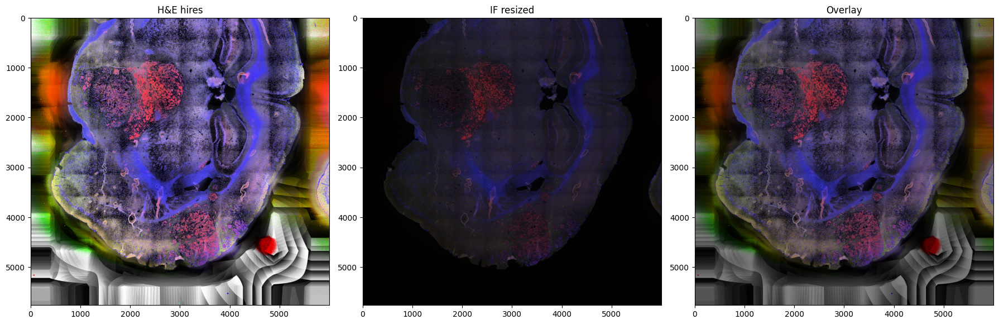

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(adata.uns["spatial"][library_id]["images"]["hires"])
axes[0].set_title("H&E hires")

# IF resized
axes[1].imshow(if_resized)
axes[1].set_title("IF resized")

# Overlay
axes[2].imshow(adata.uns["spatial"][library_id]["images"]["hires"])
axes[2].imshow(if_resized, alpha=0.5)
axes[2].set_title("Overlay")
Extract IF Intensity per Spot
plt.tight_layout()
plt.savefig("IF_HE_alignment_check.png", dpi=150)
plt.show()

In [35]:
IF_registrar_coord = IF_registrar_coord(adata)

/lsf_tmp/293180927.tmpdir/ipykernel_2615673/748813288.py:61: RuntimeWarning: Mean of empty slice.
  if_intensities.append(patch.mean())
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


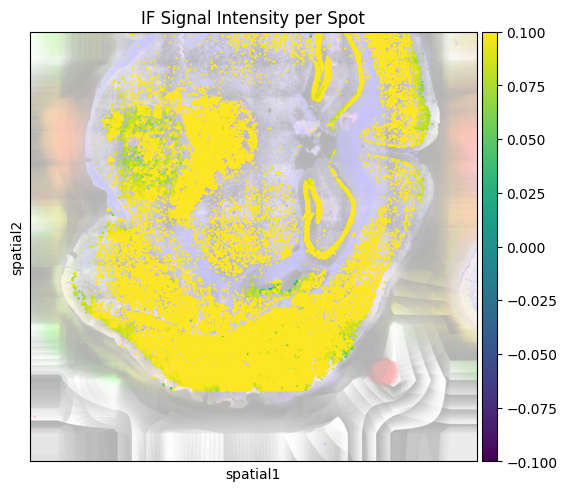

In [36]:
sq.pl.spatial_scatter(
    adata,
    color     = "IF_intensity",
    img_alpha = 0.3,
    vmin      = 0,
    vmax      = np.percentile(adata.obs["IF_intensity"], 99),
    size      = 5,
    title     = "IF Signal Intensity per Spot"
)

In [38]:
marker_table_allen_subclass,marker_allen_subclass = marker_unique_excel_subclass('/research/groups/mackgrp/home/demerson/AIB/yao_et_al_Nature_2023.xlsx','supertype_annotation')
marker_table_allen,marker_allen = marker_unique_excel('/research/groups/mackgrp/home/demerson/AIB/yao_et_al_Nature_2023.xlsx','supertype_annotation')
#remove ct with < 3 genes in adata
marker_allen = minimum_threshold_gene_filter(adata,marker_allen)

marker_allen['gfp_probe'] = ['Gfp', 'GFP', 'EGFP', 'eGFP', 'gfp', 'egfp','EGFP-L10a', 'Gfp-L10a', 'td-Tomato', 'mCherry']
tumor = {}
instance = pd.read_excel("93_core_gene_set_commonly_upregulated_in_human_and_mouse_C11orf95_RELAFUS1_driven_ependymoma.xlsx",sheet_name="Sheet1",header=None)
tumor['C11orf95_relafus1'] = instance[0].str.capitalize().tolist()


  Astro-Epen                       18/ 34 detected
  CB GABA                           5/  9 detected
  CB Glut                           1/  1 detected
  CNU-HYa GABA                     19/ 41 detected
  CNU-HYa Glut                      9/ 24 detected
  CNU-LGE GABA                     16/ 30 detected
  CNU-MGE GABA                      4/ 12 detected
  CTX-CGE GABA                      9/ 18 detected
  CTX-MGE GABA                     12/ 26 detected
  DG-IMN Glut                       2/  7 detected
  HY GABA                          11/ 38 detected
  HY Glut                           9/ 40 detected
  HY Gnrh1 Glut                     0/  1 detected
  HY MM Glut                        0/  1 detected
  IT-ET Glut                       51/115 detected
  Immune                            4/ 12 detected
  LSX GABA                         11/ 29 detected
  MB Dopa                           2/  4 detected
  MB GABA                           8/ 30 detected
  MB Glut                      

In [39]:
#method 1 scoring
for ct, genes in marker_allen.items():
    #n = score_geneset(adata, genes, ct)
    sc.tl.score_genes(
        adata,
        gene_list=genes,
        score_name= f"tlscore_{ct}",
        use_raw=False
    )

for ct, genes in tumor.items():
    sc.tl.score_genes(
        adata,
        gene_list=genes,
        score_name= f"tltumscore_{ct}",
        use_raw=False
    )

       'td-Tomato', 'mCherry'],
      dtype='object')


In [40]:
score_cols = [c for c in adata.obs.columns if c.startswith("tlscore_")]
scores = adata.obs[score_cols].copy()
#scores.columns = [c.replace("score_", "") for c in score_cols]

top2 = np.sort(scores.values, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]   # best minus second-best
adata.obs["tlcelltype_assigned"] = scores.idxmax(axis=1)
adata.obs["tlcelltype_score"] = scores.max(axis=1)
adata.obs["tlcelltype_margin"] = margin

# Require both absolute score AND separation from runner-up
low_conf = (adata.obs["tlcelltype_score"] < 0.1) | (adata.obs["tlcelltype_margin"] < 0.05)
adata.obs.loc[low_conf, "tlcelltype_assigned"] = "Unknown"

/lsf_tmp/293180927.tmpdir/ipykernel_2615673/774574772.py:11: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  gfp_adata.obs["tlcelltype_assigned"] = scores_df.idxmax(axis=1)


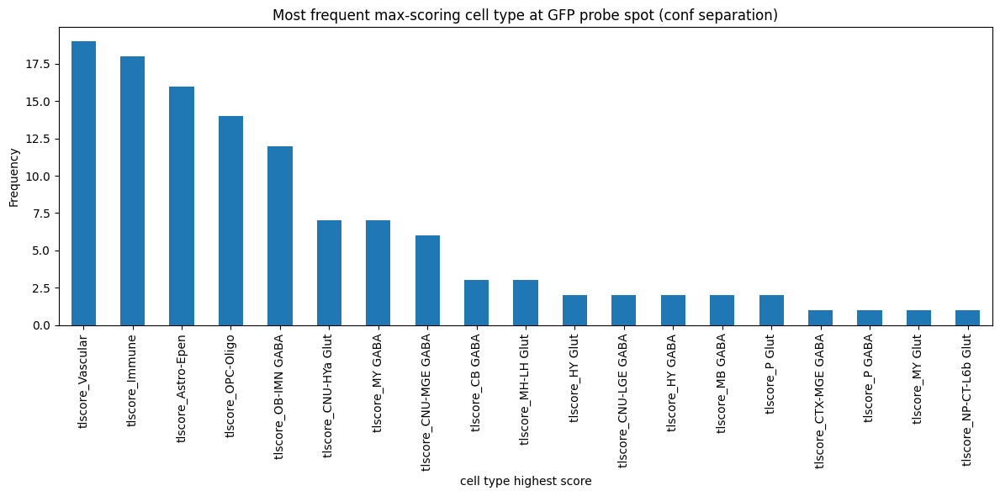

In [41]:
gfp_adata = adata[adata.obs['tlcelltype_assigned'] == "tlscore_gfp_probe"]

#reassign from gfp to class
score_cols = [c for c in gfp_adata.obs.columns if c.startswith("tlscore_")]
scores_df = gfp_adata.obs[score_cols].copy()
#gfp removed from consideration
scores_df = scores_df.drop(columns=["tlscore_gfp_probe"])

top2 = np.sort(scores_df.values, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]   # best minus second-best
gfp_adata.obs["tlcelltype_assigned"] = scores_df.idxmax(axis=1)
gfp_adata.obs["tlcelltype_score"] = scores_df.max(axis=1)
gfp_adata.obs["tlcelltype_margin"] = margin

low_conf = (gfp_adata.obs["tlcelltype_score"] < 0.1) | (gfp_adata.obs["tlcelltype_margin"] < 0.05)
gfp_adata.obs.loc[low_conf, "tlcelltype_assigned"] = "Unknown"
gfp_adata_mod =  gfp_adata[gfp_adata.obs["tlcelltype_assigned"] != "Unknown"]
counts = gfp_adata_mod.obs["tlcelltype_assigned"].value_counts()

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("cell type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring cell type at GFP probe spot (conf separation)")
plt.tight_layout()
#plt.savefig("spatial_gfp_spots_top_score_tlscore_" + label + "_bar_conf.png",dpi=300,bbox_inches="tight")


## Further subset gfp + immune into subclass

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


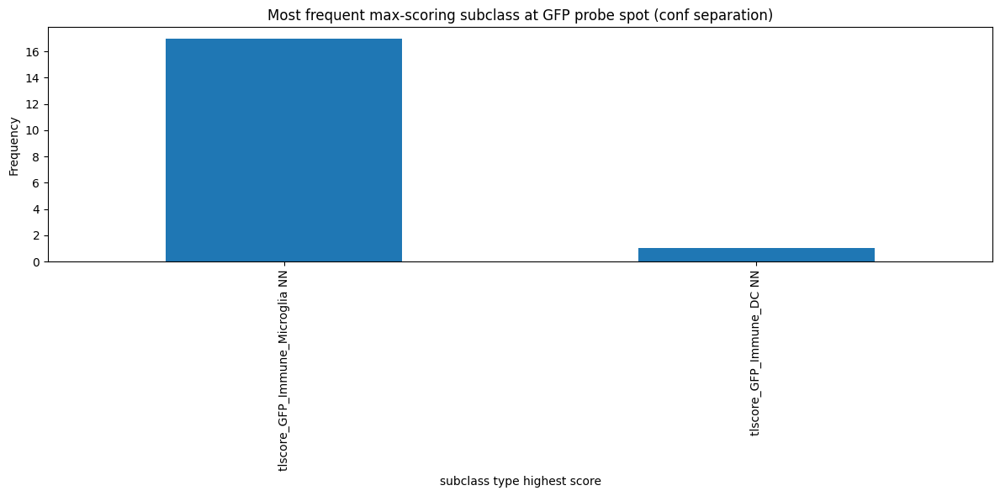

In [42]:
gfp_immune_adata = gfp_adata[gfp_adata.obs["tlcelltype_assigned"] == "tlscore_Immune"]
#marker_allen_subclass["Immune"]
for ct, genes in marker_allen_subclass["Immune"].items():
    #n = score_geneset(adata, genes, ct)
    sc.tl.score_genes(
        gfp_immune_adata,
        gene_list=genes,
        score_name= f"tlscore_GFP_Immune_{ct}",
        use_raw=False
    )

score_cols = [c for c in gfp_immune_adata.obs.columns if c.startswith("tlscore_GFP_Immune_")]
scores_df = gfp_immune_adata.obs[score_cols].copy()

top2 = np.sort(scores_df.values, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]   # best minus second-best
gfp_immune_adata.obs["tlcelltype_subclass_assigned"] = scores_df.idxmax(axis=1)
gfp_immune_adata.obs["tlcelltype_subclass_score"] = scores_df.max(axis=1)
gfp_immune_adata.obs["tlcelltype_subclass_margin"] = margin

low_conf = (gfp_immune_adata.obs["tlcelltype_subclass_score"] < 0.1) | (gfp_immune_adata.obs["tlcelltype_subclass_margin"] < 0.05)
gfp_immune_adata.obs.loc[low_conf, "tlcelltype_subclass_assigned"] = "Unknown"
gfp_immune_adata_mod =  gfp_immune_adata[gfp_immune_adata.obs["tlcelltype_subclass_assigned"] != "Unknown"]
counts = gfp_immune_adata.obs["tlcelltype_subclass_assigned"].value_counts()

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("subclass type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring subclass at GFP probe spot (conf separation)")
plt.tight_layout()

gfp_immune_adata_tlscore_conf = gfp_immune_adata.copy()


#scores_df = scores_df.drop(columns=["tlscore_gfp_probe"])

## Reassign gfp probe to max of remaining scores and plot count (no conf separation)

/lsf_tmp/293180927.tmpdir/ipykernel_2615673/859070946.py:11: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  gfp_adata.obs["tlcelltype_assigned"] = scores_df.idxmax(axis=1)


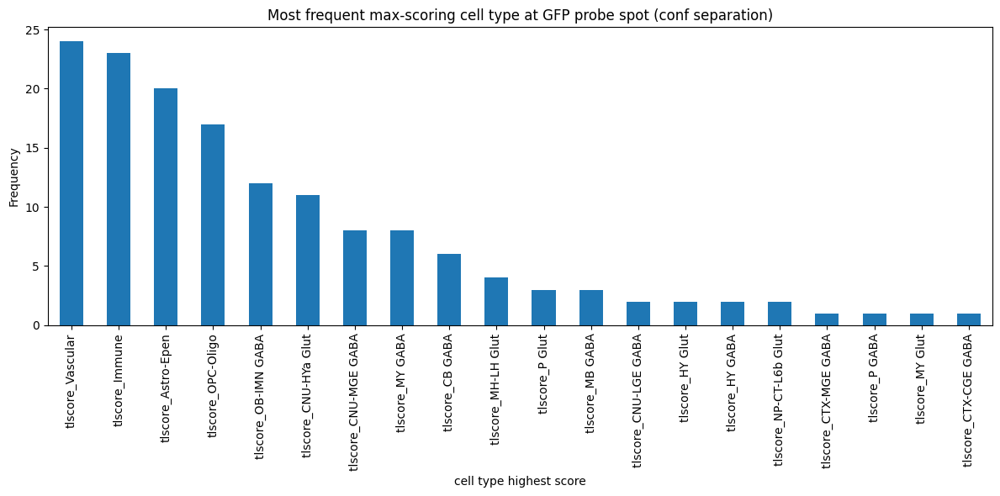

In [43]:
gfp_adata = adata[adata.obs['tlcelltype_assigned'] == "tlscore_gfp_probe"]

#reassign from gfp to class
score_cols = [c for c in gfp_adata.obs.columns if c.startswith("tlscore_")]
scores_df = gfp_adata.obs[score_cols].copy()
#gfp removed from consideration
scores_df = scores_df.drop(columns=["tlscore_gfp_probe"])

top2 = np.sort(scores_df.values, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]   # best minus second-best
gfp_adata.obs["tlcelltype_assigned"] = scores_df.idxmax(axis=1)
gfp_adata.obs["tlcelltype_score"] = scores_df.max(axis=1)
gfp_adata.obs["tlcelltype_margin"] = margin

#low_conf = (gfp_adata.obs["tlcelltype_score"] < 0.1) | (gfp_adata.obs["tlcelltype_margin"] < 0.05)
#gfp_adata.obs.loc[low_conf, "tlcelltype_assigned"] = "Unknown"
gfp_adata_mod =  gfp_adata[gfp_adata.obs["tlcelltype_assigned"] != "Unknown"]
counts = gfp_adata_mod.obs["tlcelltype_assigned"].value_counts()

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("cell type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring cell type at GFP probe spot (conf separation)")
plt.tight_layout()

#plt.savefig("spatial_gfp_spots_top_score_tlscore_" + label + "_bar.png",dpi=300,bbox_inches="tight")

## Further subset gfp + immune into subclass

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


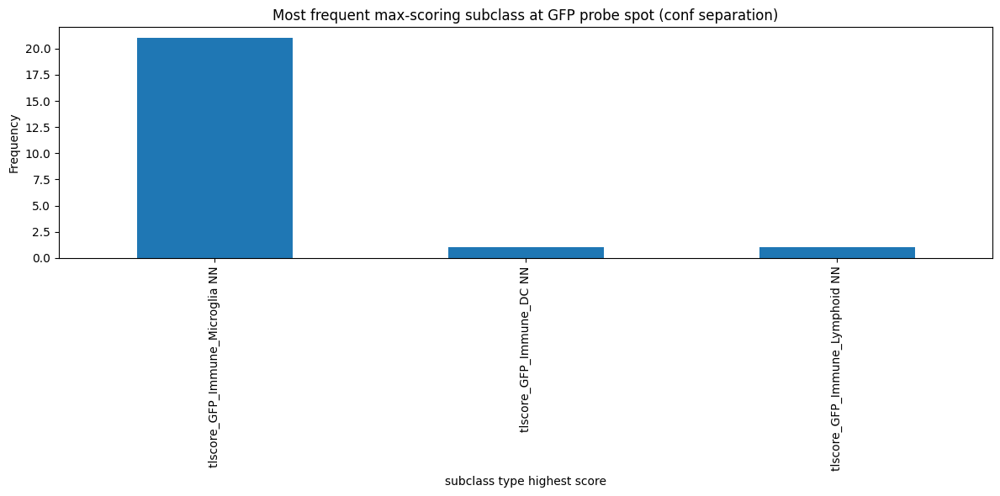

In [44]:
gfp_immune_adata = gfp_adata[gfp_adata.obs["tlcelltype_assigned"] == "tlscore_Immune"]
#marker_allen_subclass["Immune"]
for ct, genes in marker_allen_subclass["Immune"].items():
    #n = score_geneset(adata, genes, ct)
    sc.tl.score_genes(
        gfp_immune_adata,
        gene_list=genes,
        score_name= f"tlscore_GFP_Immune_{ct}",
        use_raw=False
    )

score_cols = [c for c in gfp_immune_adata.obs.columns if c.startswith("tlscore_GFP_Immune_")]
scores_df = gfp_immune_adata.obs[score_cols].copy()

top2 = np.sort(scores_df.values, axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]   # best minus second-best
gfp_immune_adata.obs["tlcelltype_subclass_assigned"] = scores_df.idxmax(axis=1)
gfp_immune_adata.obs["tlcelltype_subclass_score"] = scores_df.max(axis=1)
gfp_immune_adata.obs["tlcelltype_subclass_margin"] = margin

#low_conf = (gfp_immune_adata.obs["tlcelltype_subclass_score"] < 0.1) | (gfp_immune_adata.obs["tlcelltype_subclass_margin"] < 0.05)
#gfp_immune_adata.obs.loc[low_conf, "tlcelltype_subclass_assigned"] = "Unknown"
#gfp_immune_adata_mod =  gfp_immune_adata[gfp_immune_adata.obs["tlcelltype_subclass_assigned"] != "Unknown"]
counts = gfp_immune_adata.obs["tlcelltype_subclass_assigned"].value_counts()

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("subclass type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring subclass at GFP probe spot (conf separation)")
plt.tight_layout()

gfp_immune_adata_tlscore = gfp_immune_adata.copy()


In [45]:
adata.uns["spatial"].keys()
library_id = list(adata.uns["spatial"].keys())[0]
adata.uns["spatial"][library_id].keys()
adata.uns["spatial"][library_id]["scalefactors"]

{'bin_size_um': np.float64(8.0),
 'fiducial_diameter_fullres': np.float64(485.9152536154926),
 'microns_per_pixel': np.float64(0.6791307692948672),
 'regist_target_img_scalef': np.float64(0.51059484),
 'spot_diameter_fullres': np.float64(11.779763724011943),
 'tissue_hires_scalef': np.float64(0.51059484),
 'tissue_lowres_scalef': np.float64(0.051059484)}

In [46]:
scores = adata.obs['tlscore_gfp_probe'].values
threshold = np.percentile(scores, 70)  # top 30%

mask = scores > threshold

coords = adata.obsm["spatial"]

mean_x = coords[mask, 0].mean()
mean_y = coords[mask, 1].mean()

#print(mean_x, mean_y)
#print(coords[mask, 0])
#print(coords[mask, 1])

In [47]:
score_cols = ['tlscore_gfp_probe', 'tlscore_Astro-Epen','tlscore_Immune','tlscore_CNU-LGE GABA','tltumscore_C11orf95_relafus1']
norm_threshold = 0.07
score_cols_norm = []
for col in score_cols:
        if col not in adata.obs.columns:
            print(f"Skipping '{col}': not found in adata.obs")
            continue

        norm_col  = f"{col}_norm"

        s = adata.obs[col]
        adata.obs[norm_col] = (s - s.min()) / (s.max() - s.min())
        print(f"Normalized '{col}' → '{norm_col}'")

        adata.obs[norm_col] = adata.obs[norm_col].where(
            adata.obs[norm_col] > norm_threshold
        )
        n_passing = (adata.obs[norm_col] >= norm_threshold).sum()
        n_total   = len(adata.obs[norm_col])
        print(f"Threshold applied → '{norm_col}' | {n_passing}/{n_total} spots pass ({100*n_passing/n_total:.1f}%)")
        score_cols_norm.append(norm_col)

    

Normalized 'tlscore_gfp_probe' → 'tlscore_gfp_probe_norm'
Threshold applied → 'tlscore_gfp_probe_norm' | 151/78284 spots pass (0.2%)
Normalized 'tlscore_Astro-Epen' → 'tlscore_Astro-Epen_norm'
Threshold applied → 'tlscore_Astro-Epen_norm' | 77787/78284 spots pass (99.4%)
Normalized 'tlscore_Immune' → 'tlscore_Immune_norm'
Threshold applied → 'tlscore_Immune_norm' | 75948/78284 spots pass (97.0%)
Normalized 'tlscore_CNU-LGE GABA' → 'tlscore_CNU-LGE GABA_norm'
Threshold applied → 'tlscore_CNU-LGE GABA_norm' | 77587/78284 spots pass (99.1%)
Normalized 'tltumscore_C11orf95_relafus1' → 'tltumscore_C11orf95_relafus1_norm'
Threshold applied → 'tltumscore_C11orf95_relafus1_norm' | 78269/78284 spots pass (100.0%)


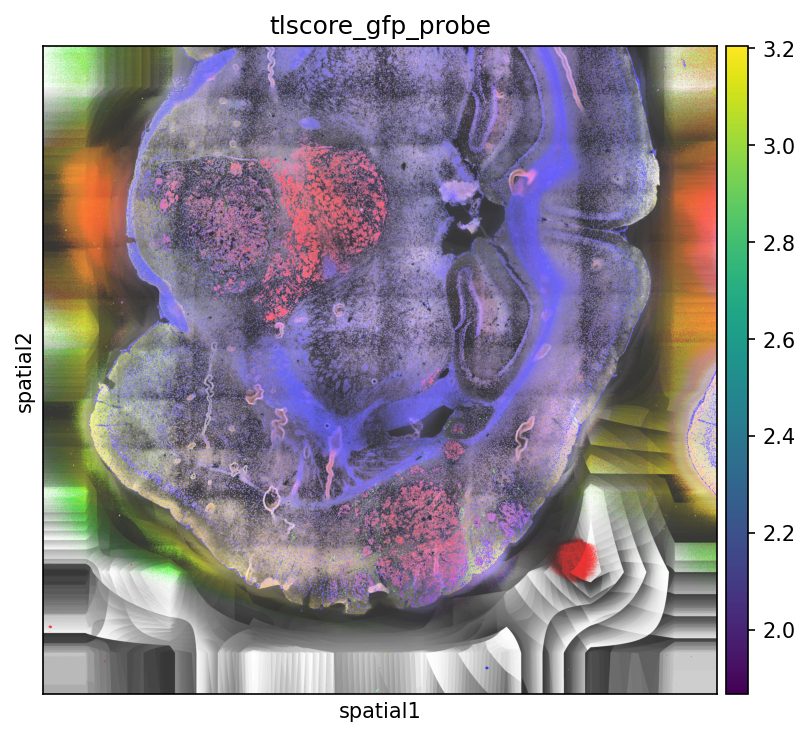

In [48]:
threshold = 0
adata_filtered = adata[adata.obs["tlscore_gfp_probe"] > threshold].copy()

sq.pl.spatial_scatter(
    adata_filtered,
    img_res_key= "hires",
    img_alpha = 0.8,
    color='tlscore_gfp_probe',
    size=1.2,
    alpha=1.0,
    dpi=150,
    title='tlscore_gfp_probe',
)

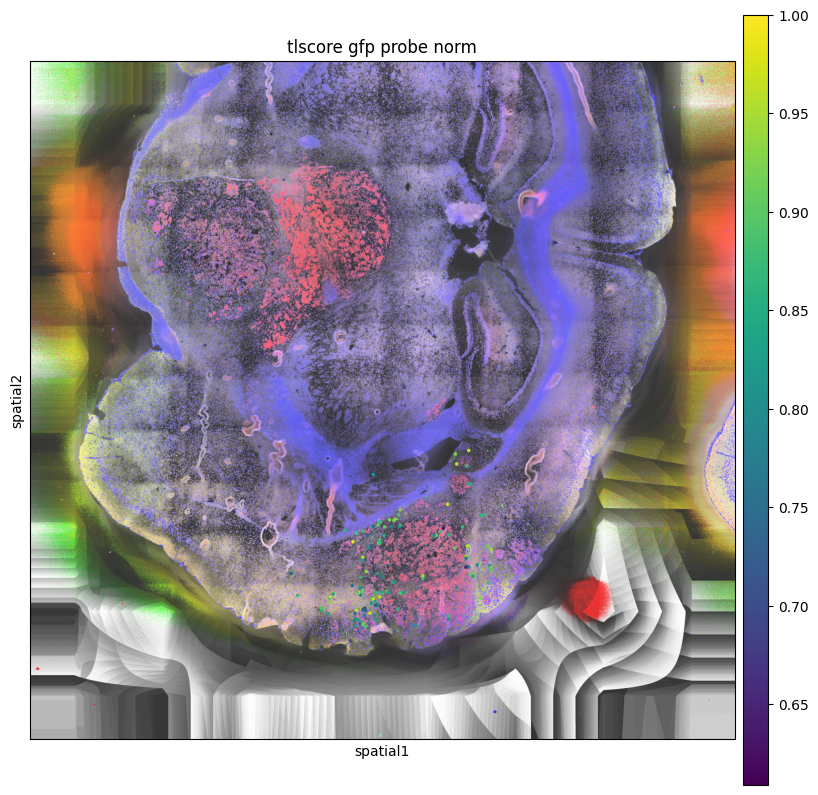

In [49]:
#threshold = 0.07
#adata_filtered = adata[adata.obs["tlscore_gfp_probe_norm"] > threshold].copy()
fig, ax = plt.subplots(figsize=(10, 10))

sq.pl.spatial_scatter(
    adata_filtered,
    img_res_key="hires",
    img_alpha = 0.8,
    color='tlscore_gfp_probe_norm',
    size=5.0,
    alpha=1.0,
    dpi=300,
    ax = ax,
    title='tlscore gfp probe norm',
)

ax.set_facecolor("none")
fig.patch.set_facecolor("none")

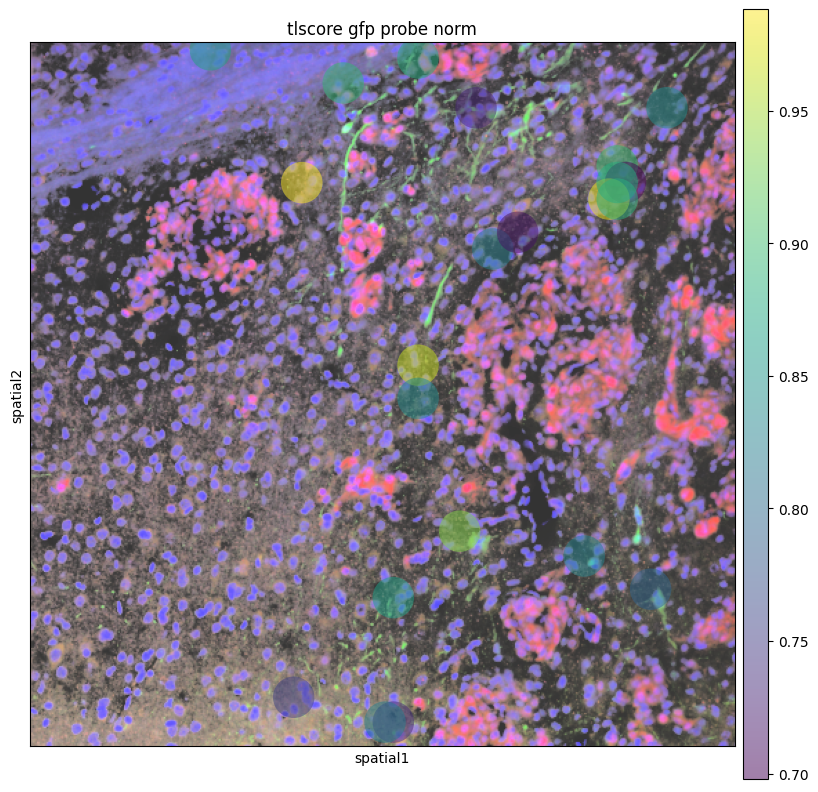

In [60]:
#select_scores = ['tlscore_gfp_probe_norm','tlscore_Astro-Epen_norm','tlscore_Immune_norm','tlscore_CNU-LGE GABA_norm','tltumscore_C11orf95_relafus1_norm']
x_center = 5500 #6140
y_center = 8309 #8309
half_width = 500
half_height = 500


x_min = x_center - half_width
y_min = y_center - half_height
x_max = x_center + half_width
y_max = y_center + half_height


#crop = (x_min, y_min,y_min,y_max)
crop = (x_min, y_min,x_max,y_max)

fig, ax = plt.subplots(figsize=(10, 10))

sq.pl.spatial_scatter(
    adata_filtered,
    img_res_key="hires",
    img_alpha = 0.8,
    color='tlscore_gfp_probe_norm',
    crop_coord=crop,
    size=5.0,
    alpha=0.5,
    dpi=300,
    ax = ax,
    title='tlscore gfp probe norm',
)

ax.set_facecolor("none")
fig.patch.set_facecolor("none")

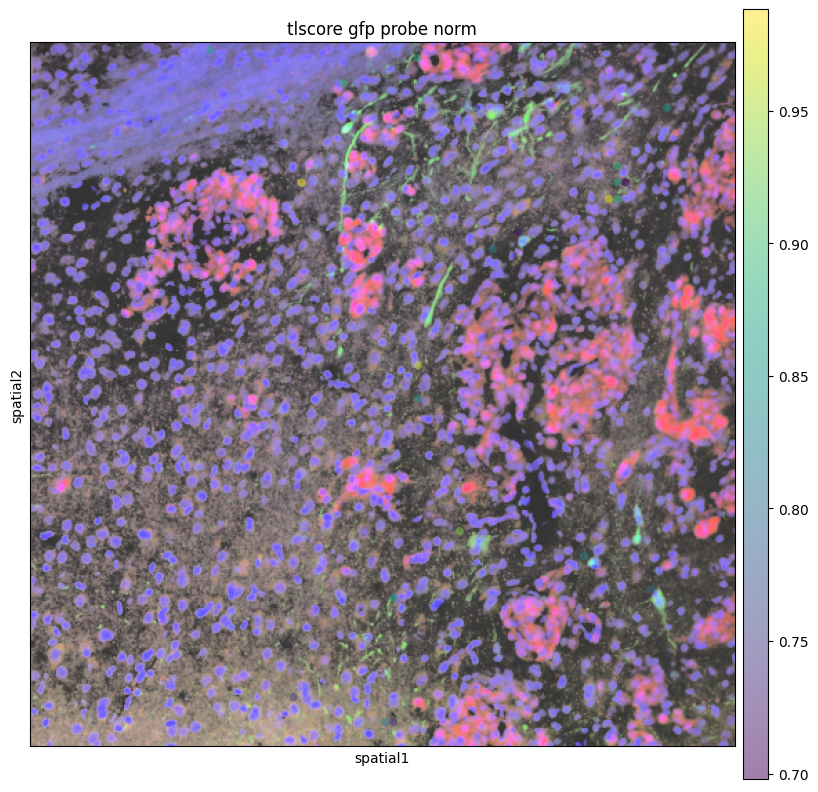

In [62]:
x_center = 5500 #6140
y_center = 8309 #8309
half_width = 500
half_height = 500


x_min = x_center - half_width
y_min = y_center - half_height
x_max = x_center + half_width
y_max = y_center + half_height


#crop = (x_min, y_min,y_min,y_max)
crop = (x_min, y_min,x_max,y_max)

fig, ax = plt.subplots(figsize=(10, 10))

sq.pl.spatial_scatter(
    adata,
    img_res_key="hires",
    img_alpha = 0.8,
    color='tlscore_gfp_probe_norm',
    crop_coord=crop,
    size=2.0,
    alpha=0.5,
    dpi=300,
    ax = ax,
    title='tlscore gfp probe norm',
)

ax.set_facecolor("none")
fig.patch.set_facecolor("none")

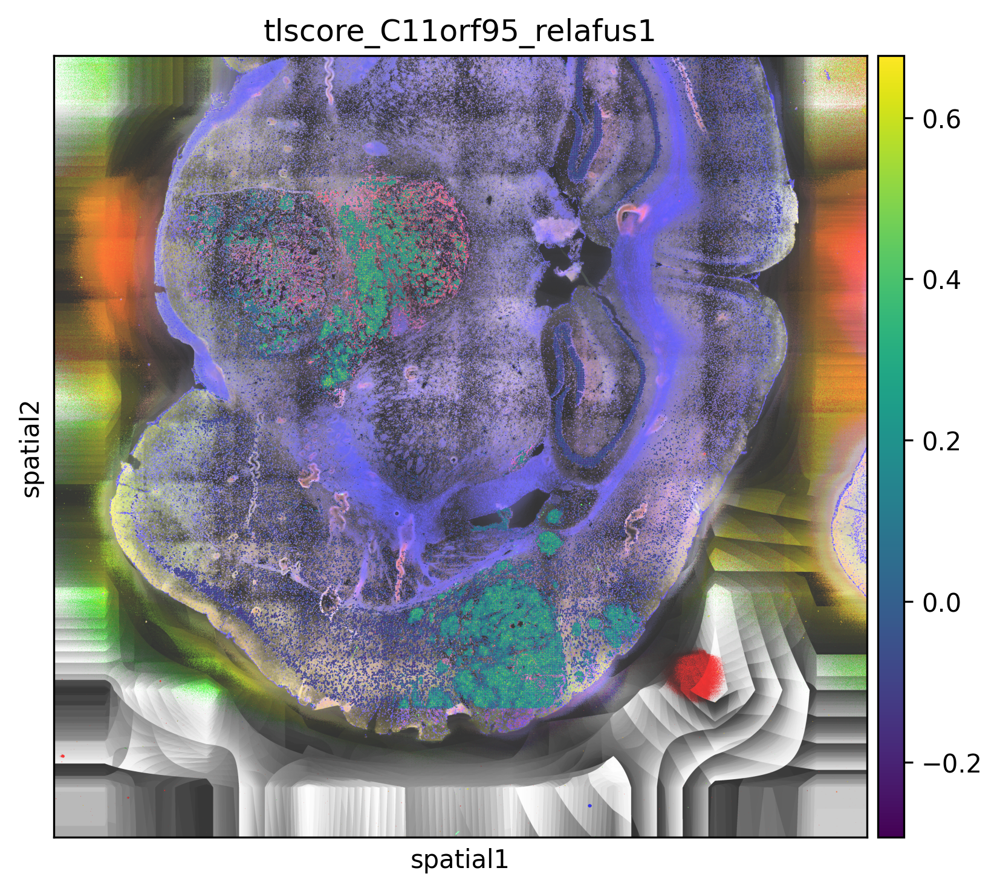

In [50]:
sq.pl.spatial_scatter(
    adata,
    img_res_key="hires",
    img_alpha = 0.8,
    color='tltumscore_C11orf95_relafus1',
    size=1.2,
    alpha=1.0,
    dpi=300,
    title='tlscore_C11orf95_relafus1',
)

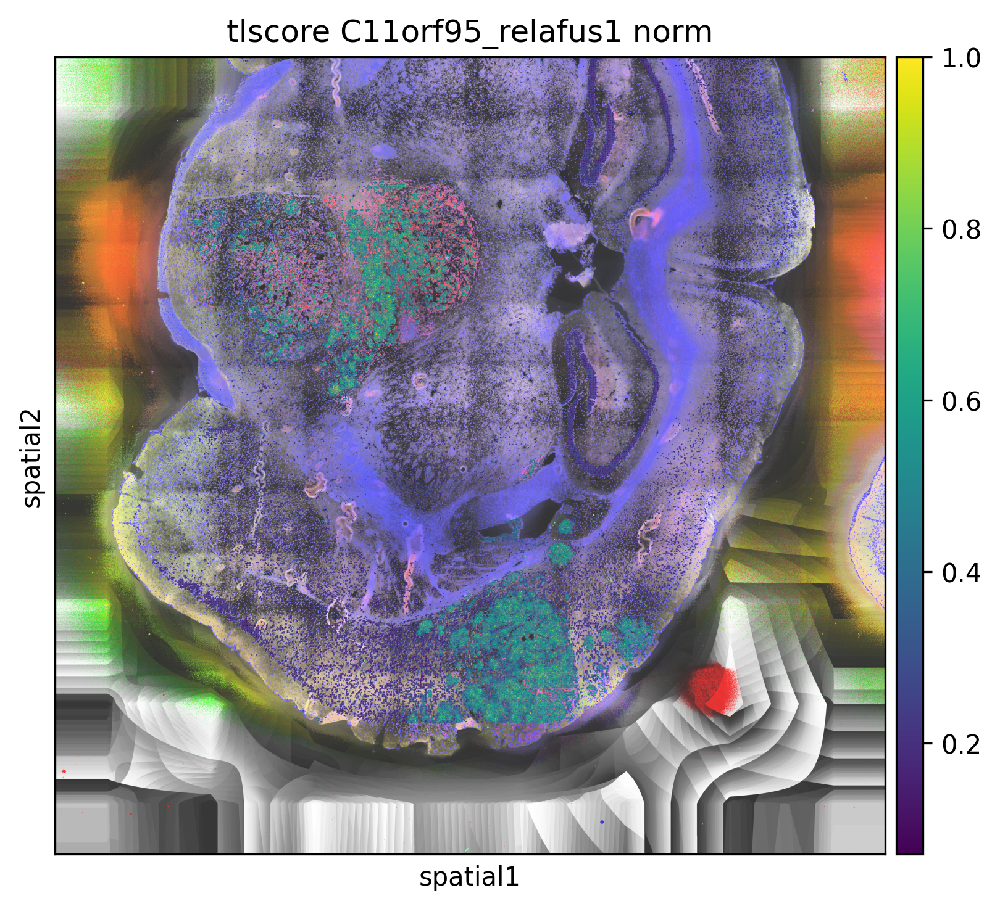

In [51]:
sq.pl.spatial_scatter(
    adata,
    img_res_key="hires",
    img_alpha = 0.8,
    color='tltumscore_C11orf95_relafus1_norm',
    size=1.2,
    alpha=1.0,
    dpi=300,
    title='tlscore C11orf95_relafus1 norm',
)

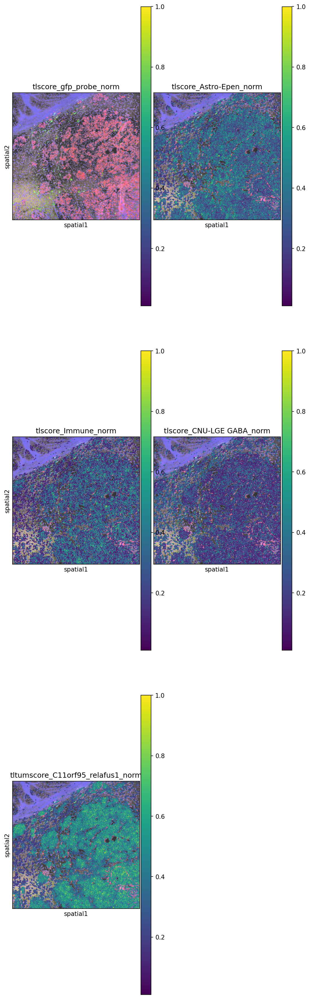

In [54]:
select_scores = ['tlscore_gfp_probe_norm','tlscore_Astro-Epen_norm','tlscore_Immune_norm','tlscore_CNU-LGE GABA_norm','tltumscore_C11orf95_relafus1_norm']

x_center = 6140
y_center = 8309
half_width = 1000
half_height = 1000


x_min = x_center - half_width
y_min = y_center - half_height
x_max = x_center + half_width
y_max = y_center + half_height


#crop = (x_min, y_min,y_min,y_max)
crop = (x_min, y_min,x_max,y_max)

n = len(select_scores)
ncols = 2  # fewer columns → larger panels
nrows = math.ceil(n / ncols)
sq.pl.spatial_scatter(
    adata,
    img_res_key="hires",
    img_alpha = 0.8,
    color=select_scores,
    size=1.2,
    alpha=1.0,
    crop_coord=crop,
    ncols=ncols,
    figsize=(2 * ncols, 3 * nrows),  # ~6 inches per panel
    wspace=0.01,  #0.15
    hspace=0.15,  #0.15
    dpi=150,
    vmin= 0.01,
    vmax= 1.0,  #3.0
    title=select_scores,
)


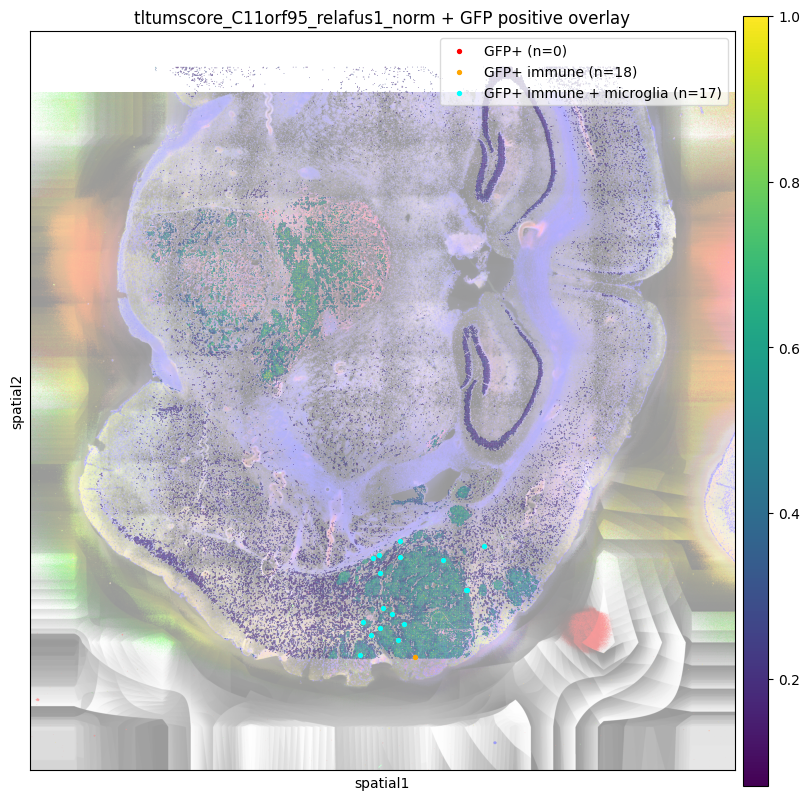

In [35]:
#Define threshold and binary column

score_col = "tlscore_gfp_probe_norm"
base_col  = "tltumscore_C11orf95_relafus1_norm"  
microglia = "tlscore_GFP_Immune_Microglia NN"
threshold = np.percentile(adata.obs[score_col], 70)

mask = adata.obs[score_col].values > threshold
mask_microglia = gfp_immune_adata_tlscore_conf.obs["tlcelltype_subclass_assigned"] == microglia

#Get scaled coordinates
library_id = list(adata.uns["spatial"].keys())[0]
scale = adata.uns["spatial"][library_id]["scalefactors"]["tissue_hires_scalef"]
coords = adata.obsm["spatial"] * scale

#Get scaled coordinates for microglia
library_id_microglia = list(gfp_immune_adata_tlscore_conf.uns["spatial"].keys())[0]
scale_microglia = gfp_immune_adata_tlscore_conf.uns["spatial"][library_id]["scalefactors"]["tissue_hires_scalef"]
coords_immunity = gfp_immune_adata_tlscore_conf.obsm["spatial"] * scale

#Base layer: continuous score of your marker
fig, ax = plt.subplots(figsize=(10, 10))

sq.pl.spatial_scatter(
    adata,
    img_res_key="hires",
    color=base_col,
    img_alpha = 0.4,
    ax=ax,
    title=f"{base_col} + GFP positive overlay",
)

#Overlay: solid red only where gfp_positive
ax.scatter(
    coords[mask, 0],
    coords[mask, 1],
    c="red",
    s=8,
    alpha=1.0,
    zorder=5,
    label=f"GFP+ (n={mask.sum()})",
)

#Overlay: solid orange only where gfp_positive + immune
ax.scatter(
    coords_immunity[:, 0],
    coords_immunity[:, 1],
    c="orange",
    s=8,
    alpha=1.0,
    zorder=5,
    label=f"GFP+ immune (n={len(gfp_immune_adata_tlscore_conf.obs)})",
)


#Overlay: solid yellow only where gfp_positive + microglia + immune
ax.scatter(
    coords_immunity[mask_microglia, 0],
    coords_immunity[mask_microglia, 1],
    c="cyan",
    s=8,
    alpha=1.0,
    zorder=5,
    label=f"GFP+ immune + microglia (n={mask_microglia.sum()})",
)


ax.legend(fontsize=10, framealpha=0.7)

#plt.savefig("gfp_on_astro.png", dpi=200, bbox_inches="tight")
plt.show()

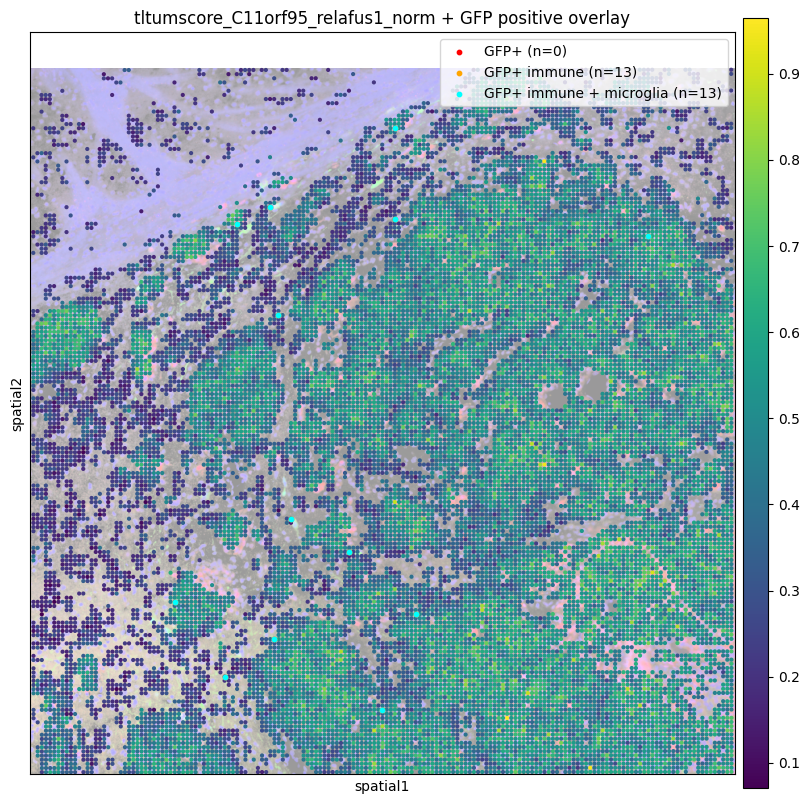

In [36]:
x_center = 6140
y_center = 8309
half_width = 1000
half_height = 1000
x_min = x_center - half_width
y_min = y_center - half_height
x_max = x_center + half_width
y_max = y_center + half_height
crop = (x_min, y_min, x_max, y_max)   # ← fixed

score_col = "tlscore_gfp_probe_norm"
base_col  = "tltumscore_C11orf95_relafus1_norm"
microglia = "tlscore_GFP_Immune_Microglia NN"

threshold = np.percentile(adata.obs[score_col], 70)
mask = adata.obs[score_col].values > threshold
mask_microglia = gfp_immune_adata_tlscore_conf.obs["tlcelltype_subclass_assigned"] == microglia

library_id = list(adata.uns["spatial"].keys())[0]
scale = adata.uns["spatial"][library_id]["scalefactors"]["tissue_hires_scalef"]
# Try raw coords first (no scale factor)
coords = adata.obsm["spatial"]

library_id_microglia = list(gfp_immune_adata_tlscore_conf.uns["spatial"].keys())[0]
scale_microglia = gfp_immune_adata_tlscore_conf.uns["spatial"][library_id]["scalefactors"]["tissue_hires_scalef"]
coords_microglia = gfp_immune_adata_tlscore_conf.obsm["spatial"]


fig, ax = plt.subplots(figsize=(10, 10))
sq.pl.spatial_scatter(
    adata,
    img_res_key="hires",
    img_alpha = 0.4, 
    color=base_col,
    crop_coord=crop,
    ax=ax,
    title=f"{base_col} + GFP positive overlay",
)

# Squidpy maps crop region → 0-1020 pixel space
# So we need: (coord - crop_min) * scale → image pixels → squidpy axis
coords_raw = adata.obsm["spatial"]   # raw spatial coords

# Filter to spots within the crop window first
in_crop = (
    (coords_raw[:, 0] >= x_min) & (coords_raw[:, 0] <= x_max) &
    (coords_raw[:, 1] >= y_min) & (coords_raw[:, 1] <= y_max)
)

combined_mask = mask & in_crop

# Then shift and scale
coords_crop = coords_raw.copy()
coords_crop[:, 0] = (coords_raw[:, 0] - x_min) * scale
coords_crop[:, 1] = (coords_raw[:, 1] - y_min) * scale

ax.scatter(
    coords_crop[combined_mask, 0],
    coords_crop[combined_mask, 1],
    c="red",
    s=10,
    alpha=1.0,
    zorder=5,
    label=f"GFP+ (n={combined_mask.sum()})",
)

coords_immunity_raw = gfp_immune_adata_tlscore_conf.obsm["spatial"]

in_crop_immunity = (
    (coords_immunity_raw[:, 0] >= x_min) & (coords_immunity_raw[:, 0] <= x_max) &
    (coords_immunity_raw[:, 1] >= y_min) & (coords_immunity_raw[:, 1] <= y_max)
)

combined_mask_microglia = mask_microglia & in_crop_immunity


# Then shift and scale
coords_crop_immunity = coords_immunity_raw.copy()
coords_crop_immunity[:, 0] = (coords_immunity_raw[:, 0] - x_min) * scale
coords_crop_immunity[:, 1] = (coords_immunity_raw[:, 1] - y_min) * scale

ax.scatter(
    coords_crop_immunity[in_crop_immunity, 0],
    coords_crop_immunity[in_crop_immunity, 1],
    c="orange",
    s=10,
    alpha=1.0,
    zorder=5,
    label=f"GFP+ immune (n={in_crop_immunity.sum()})",
)

ax.scatter(
    coords_crop_immunity[combined_mask_microglia, 0],
    coords_crop_immunity[combined_mask_microglia, 1],
    c="cyan",
    s=10,
    alpha=1.0,
    zorder=5,
    label=f"GFP+ immune + microglia (n={combined_mask_microglia.sum()})",
)

ax.legend(fontsize=10)
plt.show()

## Isolate position in distribution for gfp spots in fusion scoring distribution

In [37]:
score_col = "tlscore_gfp_probe_norm"
base_col  = "tltumscore_C11orf95_relafus1_norm"
threshold = np.percentile(adata.obs[score_col], 70)
mask = adata.obs[score_col].values > threshold

mask[mask]


array([], dtype=bool)

In [38]:
adata.obs[base_col].values[mask]

array([], dtype=float64)

In [39]:
score_col = "tlscore_gfp_probe_norm"
base_col  = "tltumscore_C11orf95_relafus1_norm"
threshold = np.percentile(adata.obs[score_col], 70)
mask = adata.obs[score_col].values > threshold

#isolate fusion signature scores at location with GFP
gfp_positive_base_scores = adata.obs[base_col].values[mask]
#print(gfp_positive_base_scores)
all_base_scores = adata.obs[base_col].values
#print(all_base_scores)

print(f"Number of GFP+ spots: {mask.sum()}")
print(f"GFP+ {base_col} scores — mean: {gfp_positive_base_scores.mean():.3f}, "
      f"median: {np.median(gfp_positive_base_scores):.3f}, "
      f"min: {gfp_positive_base_scores.min():.3f}, "
      f"max: {gfp_positive_base_scores.max():.3f}")

Number of GFP+ spots: 0


/lsf_tmp/293061173.tmpdir/ipykernel_2235526/188131339.py:13: RuntimeWarning: Mean of empty slice.
  print(f"GFP+ {base_col} scores — mean: {gfp_positive_base_scores.mean():.3f}, "
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,


ValueError: zero-size array to reduction operation minimum which has no identity

In [ ]:
# Plot distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: histogram overlay
axes[0].hist(all_base_scores, bins=50, color="steelblue", alpha=0.6, label="All fusion spots", density=True)
axes[0].hist(gfp_positive_base_scores, bins=30, color="red", alpha=0.7, label="GFP+ spots", density=True)
axes[0].axvline(np.median(gfp_positive_base_scores), color="red", linestyle="--", linewidth=1.5, label="GFP+ median")
axes[0].axvline(np.median(all_base_scores), color="steelblue", linestyle="--", linewidth=1.5, label="All fusion median")
axes[0].set_xlabel(base_col)
axes[0].set_ylabel("Density")
axes[0].set_title(f"{base_col} distribution\nGFP+ vs all spots")
axes[0].legend(fontsize=9)

# Panel 2: ECDF — shows exactly where GFP+ spots sit in the overall distribution
def ecdf(data):
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

x_all, y_all = ecdf(all_base_scores)
x_gfp, y_gfp = ecdf(gfp_positive_base_scores)

axes[1].plot(x_all, y_all, color="steelblue", label="All fusion spots")
axes[1].plot(x_gfp, y_gfp, color="red", label="GFP+ spots")
axes[1].set_xlabel(base_col)
axes[1].set_ylabel("Cumulative fraction")
axes[1].set_title(f"ECDF — where GFP+ spots sit\nin {base_col} distribution")
axes[1].legend(fontsize=9)

plt.tight_layout()
#plt.savefig("gfp_base_score_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

# Percentile rank of GFP+ spots within overall distribution
percentile_rank = (all_base_scores < np.median(gfp_positive_base_scores)).mean() * 100
print(f"GFP+ median {base_col} score is at the {percentile_rank:.1f}th percentile of all spots")

In [ ]:
from scipy.stats import mannwhitneyu

# Get scores for non-GFP+ spots (complement)
gfp_negative_base_scores = adata.obs[base_col].values[~mask]

# Mann-Whitney U test (one-sided: testing if GFP+ scores are higher)
stat, pval = mannwhitneyu(
    gfp_positive_base_scores,
    gfp_negative_base_scores,
    alternative="two-sided"
)

# Effect size: rank-biserial correlation
n1, n2 = len(gfp_positive_base_scores), len(gfp_negative_base_scores)
rank_biserial = 1 - (2 * stat) / (n1 * n2)

print(f"\n── Mann-Whitney U Test ──────────────────────────")
print(f"GFP+ spots      : n={n1}, median={np.median(gfp_positive_base_scores):.4f}")
print(f"GFP- spots      : n={n2}, median={np.median(gfp_negative_base_scores):.4f}")
print(f"U statistic     : {stat:.2f}")
print(f"p-value         : {pval:.4e}")
print(f"Effect size (r) : {rank_biserial:.4f}  (-1=GFP- higher, +1=GFP+ higher)")
print(f"────────────────────────────────────────────────")

## Isolate position in distribution for fusion scoring  spots in GFP 

In [ ]:
score_col = "tltumscore_C11orf95_relafus1_norm" #"tlscore_gfp_probe_norm"
base_col  = "tlscore_gfp_probe_norm" #"tltumscore_C11orf95_relafus1_norm"
threshold = np.percentile(adata.obs[score_col], 70)
mask = adata.obs[score_col].values > threshold

In [ ]:
adata.obs[score_col]

In [ ]:
score_col = "tltumscore_C11orf95_relafus1_norm" #"tlscore_gfp_probe_norm"
base_col  = "tlscore_gfp_probe_norm" #"tltumscore_C11orf95_relafus1_norm"
threshold = np.percentile(adata.obs[score_col], 70)
mask = adata.obs[score_col].values > threshold

#isolate fusion signature scores at location with GFP
gfp_positive_base_scores = adata.obs[base_col].values[mask]
#print(gfp_positive_base_scores)
all_base_scores = adata.obs[base_col].values
#print(all_base_scores)

print(f"Number of GFP+ spots: {mask.sum()}")
print(f"GFP+ {base_col} scores — mean: {gfp_positive_base_scores.mean():.3f}, "
      f"median: {np.median(gfp_positive_base_scores):.3f}, "
      f"min: {gfp_positive_base_scores.min():.3f}, "
      f"max: {gfp_positive_base_scores.max():.3f}")

In [ ]:
# Plot distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: histogram overlay
axes[0].hist(all_base_scores, bins=50, color="steelblue", alpha=0.6, label="All spots", density=True)
axes[0].hist(gfp_positive_base_scores, bins=30, color="red", alpha=0.7, label="GFP+ spots", density=True)
axes[0].axvline(np.median(gfp_positive_base_scores), color="red", linestyle="--", linewidth=1.5, label="GFP+ median")
axes[0].axvline(np.median(all_base_scores), color="steelblue", linestyle="--", linewidth=1.5, label="All median")
axes[0].set_xlabel(base_col)
axes[0].set_ylabel("Density")
axes[0].set_title(f"{base_col} distribution\nGFP+ vs all spots")
axes[0].legend(fontsize=9)

# Panel 2: ECDF — shows exactly where GFP+ spots sit in the overall distribution
def ecdf(data):
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

x_all, y_all = ecdf(all_base_scores)
x_gfp, y_gfp = ecdf(gfp_positive_base_scores)

axes[1].plot(x_all, y_all, color="steelblue", label="All spots")
axes[1].plot(x_gfp, y_gfp, color="red", label="GFP+ spots")
axes[1].set_xlabel(base_col)
axes[1].set_ylabel("Cumulative fraction")
axes[1].set_title(f"ECDF — where GFP+ spots sit\nin {base_col} distribution")
axes[1].legend(fontsize=9)

plt.tight_layout()
#plt.savefig("fusion_base_score_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

# Percentile rank of GFP+ spots within overall distribution
percentile_rank = (all_base_scores < np.median(gfp_positive_base_scores)).mean() * 100
print(f"GFP+ median {base_col} score is at the {percentile_rank:.1f}th percentile of all spots")

In [ ]:
from scipy.stats import mannwhitneyu

# Get scores for non-GFP+ spots (complement)
gfp_negative_base_scores = adata.obs[base_col].values[~mask]

# Mann-Whitney U test (one-sided: testing if GFP+ scores are higher)
stat, pval = mannwhitneyu(
    gfp_positive_base_scores,
    gfp_negative_base_scores,
    alternative="two-sided"
)

# Effect size: rank-biserial correlation
n1, n2 = len(gfp_positive_base_scores), len(gfp_negative_base_scores)
rank_biserial = 1 - (2 * stat) / (n1 * n2)

print(f"\n── Mann-Whitney U Test ──────────────────────────")
print(f"GFP+ spots      : n={n1}, median={np.median(gfp_positive_base_scores):.4f}")
print(f"GFP- spots      : n={n2}, median={np.median(gfp_negative_base_scores):.4f}")
print(f"U statistic     : {stat:.2f}")
print(f"p-value         : {pval:.4e}")
print(f"Effect size (r) : {rank_biserial:.4f}  (-1=GFP- higher, +1=GFP+ higher)")
print(f"────────────────────────────────────────────────")

## Overlay celltypes 

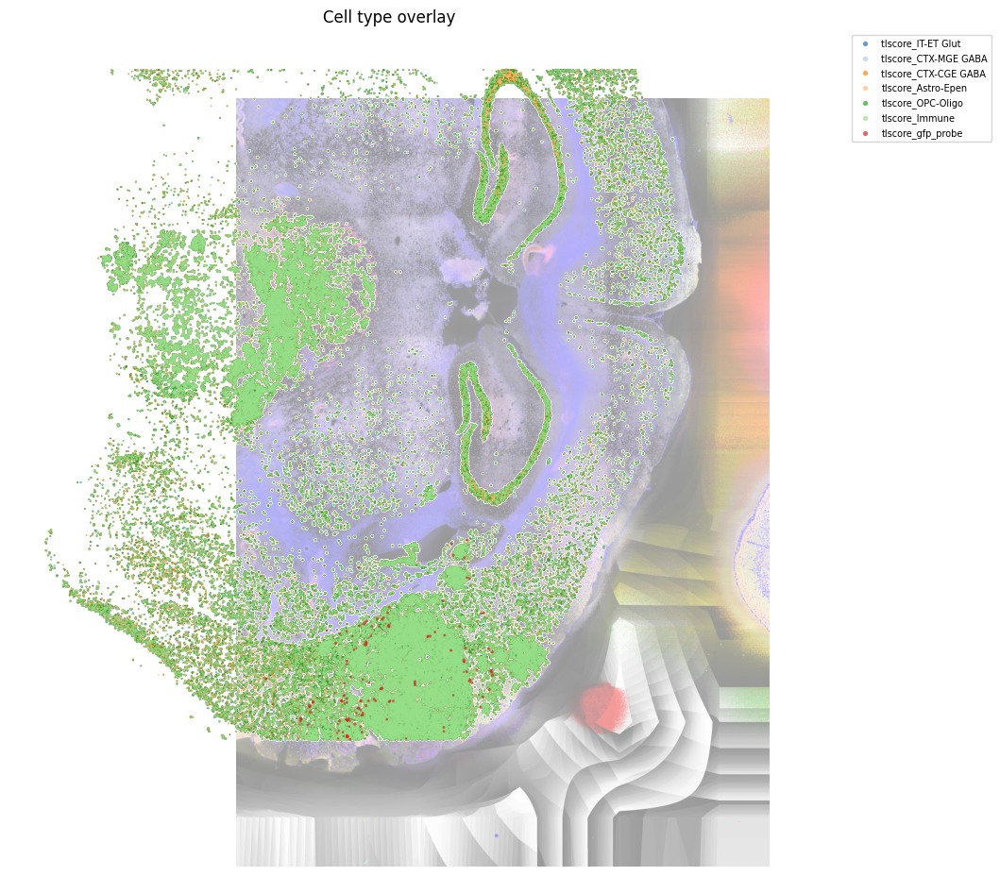

In [40]:
celltypes_to_overlay = [
    "tlscore_IT-ET Glut", "tlscore_CTX-MGE GABA", "tlscore_CTX-CGE GABA",
    "tlscore_Astro-Epen", "tlscore_OPC-Oligo", "tlscore_Immune","tlscore_gfp_probe"
]


#X range: 1102.4363256393638 to 10642.11908595422
#Y range: -423.6980255064567 to 9427.419394843508

fig = plot_celltype_overlay(
    adata,
    celltypes_to_overlay,
    crop_coord = (2000,0,9000,9000)    #(2000,0,9000,9000) works
)

#fig.savefig("celltype_overlay_Tuyu_Apr2026_846531_HD_BA_WM_C_DNB_SM_D90_5_A1_GFP_R1_8uM.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

In [41]:
for ct, genes in marker_allen.items():
    adata.obs[f"wscore_{ct}"] = weighted_score(adata, genes)

In [42]:
gfp_adata = adata[adata.obs['wscore_gfp_probe'] > 0]

## NNLS deconvolve assignment

| Aspect |	NNLS deconvolution | tl.score_genes |
|------|------|------|
| Goal  | Estimate cell-type composition	| Measure signature activity per cell |
| Input | Reference profiles + mixture expression |	Gene list + background genes | 
| Output | Fractions or abundance-like weights | Relative score per cell |
| Interpretation | “How much of each cell type is present?”	| “How active is this gene set in this cell?” | 
| Best use | Bulk / spot deconvolution | Single-cell or spatial signature scoring |

In [43]:
prop_df = nnls_deconvolve(adata, marker_allen)

In [44]:
prop_df

,nnls_Astro-Epen,nnls_CB GABA,nnls_CNU-HYa GABA,nnls_CNU-HYa Glut,nnls_CNU-LGE GABA,nnls_CNU-MGE GABA,nnls_CTX-CGE GABA,nnls_CTX-MGE GABA,nnls_HY GABA,nnls_HY Glut,...,nnls_MY GABA,nnls_MY Glut,nnls_NP-CT-L6b Glut,nnls_OB-IMN GABA,nnls_OPC-Oligo,nnls_P GABA,nnls_P Glut,nnls_TH Glut,nnls_Vascular,nnls_gfp_probe
s_008um_00469_00254-1,0.000000,0.0,0.041131,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.651436e-17,...,0.000000,0.052254,6.376720e-01,0.075503,0.000000e+00,1.108474e-01,0.000000,0.000000,0.000000,0.000000e+00
s_008um_00744_00190-1,0.000000,0.0,0.049601,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.894782e-17,...,0.000000,0.111648,0.000000e+00,0.089880,0.000000e+00,1.184520e-01,0.000000,0.000000,0.000000,0.000000e+00
s_008um_00278_00363-1,0.006580,0.0,0.022950,0.000000,0.061180,0.177240,0.000000,0.052578,0.000000,1.278234e-17,...,0.217248,0.004144,1.215363e-17,0.037392,7.013958e-02,0.000000e+00,0.021081,0.082125,0.067295,4.865948e-15
s_008um_00812_00450-1,0.097572,0.0,0.000000,0.000000,0.000000,0.000000,0.060965,0.102778,0.000000,1.721256e-18,...,0.032813,0.082675,0.000000e+00,0.000000,0.000000e+00,8.771269e-02,0.000000,0.000000,0.093649,0.000000e+00
s_008um_00818_00361-1,0.058669,0.0,0.061253,0.204546,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.000000,1.095678e-01,0.076093,0.000000e+00,1.152765e-18,0.114902,0.000000,0.000000,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s_008um_00834_00515-1,0.038154,0.0,0.020755,0.101595,0.000000,0.311332,0.000000,0.000000,0.000000,4.851717e-02,...,0.000000,0.000000,0.000000e+00,0.058362,1.092392e-01,2.233555e-02,0.000000,0.076072,0.093532,0.000000e+00
s_008um_00679_00515-1,0.030964,0.0,0.080447,0.000000,0.116341,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.033766,0.000000e+00,0.000000,3.814371e-02,1.165077e-01,0.053926,0.000000,0.000000,0.000000e+00
s_008um_00655_00610-1,0.026691,0.0,0.000000,0.087532,0.085162,0.000000,0.000000,0.093554,0.196187,1.187797e-17,...,0.000000,0.037637,1.817149e-01,0.010480,3.270474e-18,9.888532e-19,0.000000,0.000000,0.000000,0.000000e+00
s_008um_00065_00410-1,0.000000,0.0,0.251390,0.000000,0.151056,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.047107,0.000000e+00,0.114654,0.000000e+00,1.625556e-01,0.000000,0.241436,0.000000,0.000000e+00


In [45]:
new_cols = prop_df.columns.difference(adata.obs.columns)

if len(new_cols) > 0:
    adata.obs = adata.obs.join(prop_df[new_cols])
else:
    print("All columns already exist in adata.obs, skipping join.")

/lsf_tmp/293061173.tmpdir/ipykernel_2235526/1234706136.py:10: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  gfp_adata.obs["nnls_predicted_celltype"] = scores_df["predicted_celltype"]


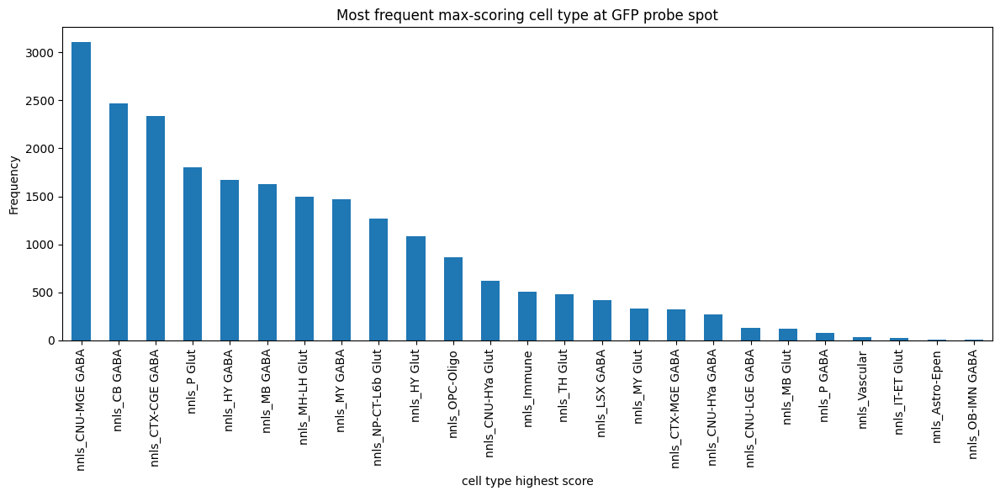

In [46]:
gfp_adata = adata[adata.obs['nnls_gfp_probe'] > 0]
gfp_scores = gfp_adata.obs['nnls_gfp_probe'].values

select_scores = ["nnls_" + k for k in marker_allen.keys()]

scores_df = gfp_adata.obs[select_scores]
scores_df = scores_df.drop(columns=["nnls_gfp_probe"])
scores_df["predicted_celltype"] = scores_df.idxmax(axis=1)
counts = scores_df["predicted_celltype"].value_counts()
gfp_adata.obs["nnls_predicted_celltype"] = scores_df["predicted_celltype"]

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("cell type highest score")
ax.set_ylabel("Frequency")
ax.set_title("Most frequent max-scoring cell type at GFP probe spot")
plt.tight_layout()

/home/demerson/.conda/envs/spatial/lib/python3.10/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


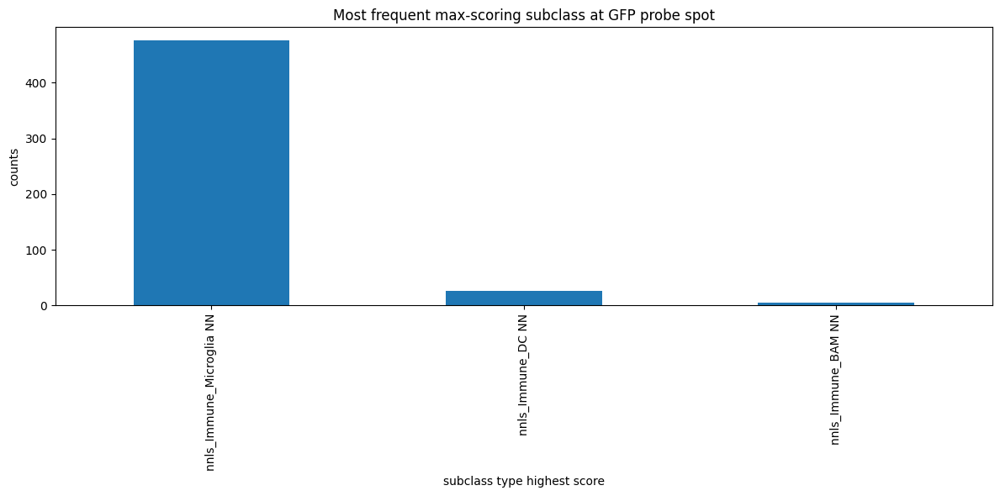

In [47]:
gfp_immune_adata = gfp_adata[gfp_adata.obs["nnls_predicted_celltype"] == "nnls_Immune"]
#marker_allen_subclass["Immune"]
for ct, genes in marker_allen_subclass["Immune"].items():
    #n = score_geneset(adata, genes, ct)
    sc.tl.score_genes(
        gfp_immune_adata,
        gene_list=genes,
        score_name= f"nnls_Immune_{ct}",
        use_raw=False
    )

score_cols = [c for c in gfp_immune_adata.obs.columns if c.startswith("nnls_Immune_")]
scores_df = gfp_immune_adata.obs[score_cols].copy()

gfp_immune_adata.obs["nnls_Immune_subclass_assigned"] = scores_df.idxmax(axis=1)
gfp_immune_adata.obs["nnls_Immune_subclass_score"] = scores_df.max(axis=1)
counts = gfp_immune_adata.obs["nnls_Immune_subclass_assigned"].value_counts()

ax = counts.plot(
        kind="bar",
        figsize=(12, 6))

ax.set_xlabel("subclass type highest score")
ax.set_ylabel("counts")
ax.set_title("Most frequent max-scoring subclass at GFP probe spot")
plt.tight_layout()

gfp_immune_adata_tlscore_nnls = gfp_immune_adata.copy()

## Plot NNLS markers

In [48]:
adata[adata.obs['nnls_gfp_probe'] > 0]

View of AnnData object with n_obs × n_vars = 22524 × 15028
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'Astro-Epen', 'CB GABA', 'CB Glut', 'CNU-HYa GABA', 'CNU-HYa Glut', 'CNU-LGE GABA', 'CNU-MGE GABA', 'CTX-CGE GABA', 'CTX-MGE GABA', 'DG-IMN Glut', 'HY GABA', 'HY Glut', 'HY Gnrh1 Glut', 'HY MM Glut', 'IT-ET Glut', 'Immune', 'LSX GABA', 'MB Dopa', 'MB GABA', 'MB Glut', 'MB-HB Sero', 'MH-LH Glut', 'MY GABA', 'MY Glut', 'NP-CT-L6b Glut', 'OB-CR Glut', 'OB-IMN GABA', 'OPC-Oligo', 'P GABA', 'P Glut', 'Pineal Glut', 'TH Glut', 'Vascular', 'gfp_probe', 'leiden', 'tlscore_Astro-Epen', 'tlscore_CB GABA', 'tlscore_CNU-HYa GABA', 'tlscore_CNU-HYa Glut', 'tlscore_CNU-LGE GABA', 'tlscore_CNU-MGE GABA', 'tlscore_CTX-CGE GABA', 'tlscore_CTX-MGE GABA', 'tlscore_HY GABA', 'tlscore

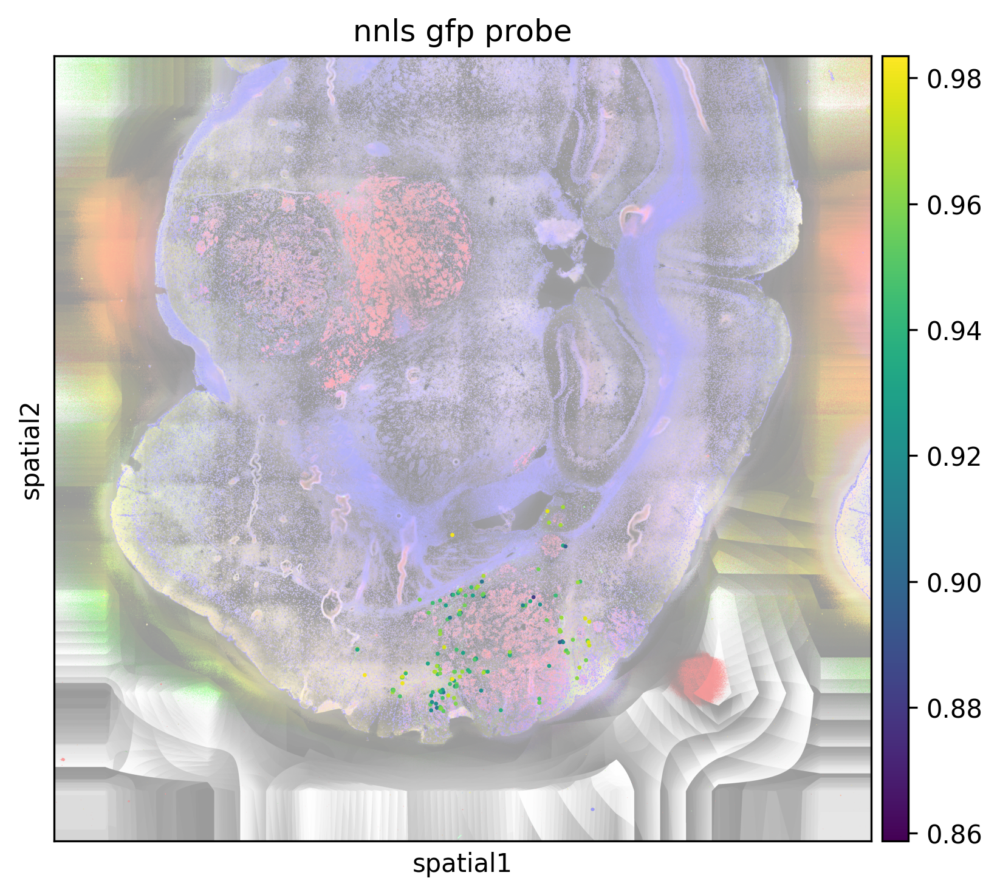

In [49]:
threshold = 0.07
adata_filtered = adata[adata.obs["nnls_gfp_probe"] > threshold].copy()

sq.pl.spatial_scatter(
    adata_filtered,
    img_res_key="hires",
    img_alpha = 0.4,
    color='nnls_gfp_probe',
    size=5.0,
    alpha=1.0,
    dpi=300,
    title='nnls gfp probe',
)

In [47]:
adata_filtered

AnnData object with n_obs × n_vars = 151 × 15028
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_counts', 'Astro-Epen', 'CB GABA', 'CB Glut', 'CNU-HYa GABA', 'CNU-HYa Glut', 'CNU-LGE GABA', 'CNU-MGE GABA', 'CTX-CGE GABA', 'CTX-MGE GABA', 'DG-IMN Glut', 'HY GABA', 'HY Glut', 'HY Gnrh1 Glut', 'HY MM Glut', 'IT-ET Glut', 'Immune', 'LSX GABA', 'MB Dopa', 'MB GABA', 'MB Glut', 'MB-HB Sero', 'MH-LH Glut', 'MY GABA', 'MY Glut', 'NP-CT-L6b Glut', 'OB-CR Glut', 'OB-IMN GABA', 'OPC-Oligo', 'P GABA', 'P Glut', 'Pineal Glut', 'TH Glut', 'Vascular', 'gfp_probe', 'leiden', 'tlscore_Astro-Epen', 'tlscore_CB GABA', 'tlscore_CNU-HYa GABA', 'tlscore_CNU-HYa Glut', 'tlscore_CNU-LGE GABA', 'tlscore_CNU-MGE GABA', 'tlscore_CTX-CGE GABA', 'tlscore_CTX-MGE GABA', 'tlscore_HY GABA', 'tlscore_HY Glut',

# Reanalyze spots outside GFP ...

Reanalyze intersection of GFP with immune spots more broadly?  
- Idea 1: "Maybe we can make a threshold like if 2 spots are next to each other then we call them the same GFP+ immune cells".  Proximity based rabies spot as an active immune locus

In [48]:
#adata = high_confidence_assignment(adata, marker_allen,score_pct=75, min_methdods=2) 